In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder

df = pd.read_csv("/home/ander/Documentos/Universidad/ML/proyecto/Datasets/train_processed.csv")

def one_hot_encode_categorical(df, column):
    encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    encoded_column = encoder.fit_transform(df[[column]])    
    encoded_df = pd.DataFrame(encoded_column, columns=encoder.get_feature_names_out([column]))
    df = pd.concat([df, encoded_df], axis=1)
    df = df.drop(column, axis=1)
    return df, encoder

categorical_columns = ['Geography']
df = df.copy()  

encoders = {}
for column in categorical_columns:
    df, enconder = one_hot_encode_categorical(df, column)
    encoders[column] = enconder
    
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

X = df.drop(columns=["Exited"])
y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

OPTUNA

In [3]:
import optuna
from optuna import create_study
from optuna.samplers import TPESampler
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE, ADASYN
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def objective_rf(trial):
    sampler_name = trial.suggest_categorical('sampler', ['None', 'SMOTE', 'ADASYN'])
    if sampler_name == 'SMOTE':
        sampler = SMOTE(random_state=42)
    elif sampler_name == 'ADASYN':
        sampler = ADASYN(random_state=42)
    else:
        sampler = None
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'bootstrap': trial.suggest_categorical('bootstrap', [True, False])
    }
    model = RandomForestClassifier(**params, random_state=42)
    X_train_use, X_test_use = X_train, X_test
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_use, y_train)
    else:
        X_res, y_res = X_train_use, y_train
    model.fit(X_res, y_res)
    y_pred_proba = model.predict_proba(X_test_use)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_gb(trial):
    sampler_name = trial.suggest_categorical('sampler', ['None', 'SMOTE', 'ADASYN'])
    if sampler_name == 'SMOTE':
        sampler = SMOTE(random_state=42)
    elif sampler_name == 'ADASYN':
        sampler = ADASYN(random_state=42)
    else:
        sampler = None
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0)
    }
    model = GradientBoostingClassifier(**params, random_state=42)
    X_train_use, X_test_use = X_train, X_test
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_use, y_train)
    else:
        X_res, y_res = X_train_use, y_train
    model.fit(X_res, y_res)
    y_pred_proba = model.predict_proba(X_test_use)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_xgb(trial):
    sampler_name = trial.suggest_categorical('sampler', ['None', 'SMOTE', 'ADASYN'])
    if sampler_name == 'SMOTE':
        sampler = SMOTE(random_state=42)
    elif sampler_name == 'ADASYN':
        sampler = ADASYN(random_state=42)
    else:
        sampler = None
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5)
    }
    model = XGBClassifier(**params, random_state=42, use_label_encoder=False, eval_metric='logloss')
    X_train_use, X_test_use = X_train, X_test
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_use, y_train)
    else:
        X_res, y_res = X_train_use, y_train
    model.fit(X_res, y_res)
    y_pred_proba = model.predict_proba(X_test_use)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_lgb(trial):
    sampler_name = trial.suggest_categorical('sampler', ['None', 'SMOTE', 'ADASYN'])
    if sampler_name == 'SMOTE':
        sampler = SMOTE(random_state=42)
    elif sampler_name == 'ADASYN':
        sampler = ADASYN(random_state=42)
    else:
        sampler = None
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 1, 20),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 2),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 2)
    }
    model = LGBMClassifier(**params, random_state=42)
    X_train_use, X_test_use = X_train, X_test
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_use, y_train)
    else:
        X_res, y_res = X_train_use, y_train
    model.fit(X_res, y_res)
    y_pred_proba = model.predict_proba(X_test_use)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_lr(trial):
    sampler_name = trial.suggest_categorical('sampler', ['None', 'SMOTE', 'ADASYN'])
    if sampler_name == 'SMOTE':
        sampler = SMOTE(random_state=42)
    elif sampler_name == 'ADASYN':
        sampler = ADASYN(random_state=42)
    else:
        sampler = None
    params = {
        'C': trial.suggest_float('C', 0.01, 10.0),
        'penalty': trial.suggest_categorical('penalty', ['l1', 'l2']),
        'solver': trial.suggest_categorical('solver', ['liblinear', 'saga']),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
    }
    model = LogisticRegression(**params, random_state=42, max_iter=2000)
    X_train_use, X_test_use = X_train_scaled, X_test_scaled
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_use, y_train)
    else:
        X_res, y_res = X_train_use, y_train
    model.fit(X_res, y_res)
    y_pred_proba = model.predict_proba(X_test_use)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_et(trial):
    sampler_name = trial.suggest_categorical('sampler', ['None', 'SMOTE', 'ADASYN'])
    if sampler_name == 'SMOTE':
        sampler = SMOTE(random_state=42)
    elif sampler_name == 'ADASYN':
        sampler = ADASYN(random_state=42)
    else:
        sampler = None
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None])
    }
    model = ExtraTreesClassifier(**params, random_state=42)
    X_train_use, X_test_use = X_train, X_test
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_use, y_train)
    else:
        X_res, y_res = X_train_use, y_train
    model.fit(X_res, y_res)
    y_pred_proba = model.predict_proba(X_test_use)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score



In [4]:
from imblearn.ensemble import EasyEnsembleClassifier, RUSBoostClassifier, BalancedBaggingClassifier, BalancedRandomForestClassifier
from sklearn.metrics import roc_auc_score

def objective_easyensemble(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300)
    }
    model = EasyEnsembleClassifier(
        n_estimators=params['n_estimators'],
        random_state=42, n_jobs=8
    )
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_rusboost(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10)
    }
    from sklearn.tree import DecisionTreeClassifier
    model = RUSBoostClassifier(
        n_estimators=params['n_estimators'],
        learning_rate=params['learning_rate'],
        estimator=DecisionTreeClassifier(max_depth=params['max_depth'], random_state=42),
        random_state=42
    )
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_balancedbagging(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_samples': trial.suggest_float('max_samples', 0.5, 1.0),
        'max_features': trial.suggest_float('max_features', 0.5, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10)
    }
    from sklearn.tree import DecisionTreeClassifier
    model = BalancedBaggingClassifier(
        n_estimators=params['n_estimators'],
        max_samples=params['max_samples'],
        max_features=params['max_features'],
        estimator=DecisionTreeClassifier(max_depth=params['max_depth'], random_state=42),
        random_state=42, n_jobs=8
    )
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

def objective_balancedrf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None])
    }
    model = BalancedRandomForestClassifier(
        n_estimators=params['n_estimators'],
        max_depth=params['max_depth'],
        min_samples_split=params['min_samples_split'],
        min_samples_leaf=params['min_samples_leaf'],
        max_features=params['max_features'],
        random_state=42, n_jobs=8
    )
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    return auc_score

In [ ]:
# Optuna para EasyEnsembleClassifier
study_easyensemble = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_easyensemble.optimize(objective_easyensemble, n_trials=250)
print("EasyEnsembleClassifier best params:", study_easyensemble.best_params)

In [ ]:
# Optuna para RUSBoostClassifier
study_rusboost = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_rusboost.optimize(objective_rusboost, n_trials=250)
print("RUSBoostClassifier best params:", study_rusboost.best_params)

In [ ]:
# Optuna para BalancedBaggingClassifier
study_balancedbagging = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_balancedbagging.optimize(objective_balancedbagging, n_trials=250)
print("BalancedBaggingClassifier best params:", study_balancedbagging.best_params)


In [ ]:

# Optuna para BalancedRandomForestClassifier
study_balancedrf = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_balancedrf.optimize(objective_balancedrf, n_trials=250)
print("BalancedRandomForestClassifier best params:", study_balancedrf.best_params)

In [ ]:

# Ejecuta cada estudio por separado
study_rf = create_study(direction='maximize', sampler=TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=100)
print("RandomForest:", study_rf.best_params)



In [ ]:
study_gb = create_study(direction='maximize', sampler=TPESampler(seed=42))
study_gb.optimize(objective_gb, n_trials=100)
print("GradientBoosting:", study_gb.best_params)

In [ ]:

study_xgb = create_study(direction='maximize', sampler=TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=100)
print("XGBoost:", study_xgb.best_params)


In [ ]:
study_lgb = create_study(direction='maximize', sampler=TPESampler(seed=42))
study_lgb.optimize(objective_lgb, n_trials=500)
print("LightGBM:", study_lgb.best_params)



In [ ]:
study_lr = create_study(direction='maximize', sampler=TPESampler(seed=42))
study_lr.optimize(objective_lr, n_trials=100)
print("LogisticRegression:", study_lr.best_params)


In [ ]:
study_et = create_study(direction='maximize', sampler=TPESampler(seed=42))
study_et.optimize(objective_et, n_trials=100)
print("ExtraTrees:", study_et.best_params)

(IMBLEARN_EEC)

In [3]:
from imblearn.ensemble import EasyEnsembleClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# Entrena el modelo EasyEnsembleClassifier con los mejores parámetros
best_eec = EasyEnsembleClassifier(
    n_estimators=59,
    random_state=42
)

best_eec.fit(X_train, y_train)
y_pred = best_eec.predict(X_test)
y_pred_proba = best_eec.predict_proba(X_test)[:, 1]

# Evaluar el modelo
auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(cm)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.9242
Accuracy: 0.8537

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.95      0.86      0.90      2388
       Churn       0.60      0.82      0.69       612

    accuracy                           0.85      3000
   macro avg       0.78      0.84      0.80      3000
weighted avg       0.88      0.85      0.86      3000

Matriz de confusión:
[[2062  326]
 [ 113  499]]
Sensibilidad: 0.8154
Especificidad: 0.8635
G-mean: 0.8391


(IMBLEARN_RUSB)

In [4]:
from imblearn.ensemble import RUSBoostClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# Entrena el modelo RUSBoostClassifier. 
# Los parámetros del estimador base (DecisionTreeClassifier) se pasan con '__'.
best_rus = RUSBoostClassifier(
    n_estimators=295,
    learning_rate=0.03169408226050428,
    random_state=42
)

best_rus.fit(X_train, y_train)
y_pred = best_rus.predict(X_test)
y_pred_proba = best_rus.predict_proba(X_test)[:, 1]

# Evaluar el modelo
auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(cm)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.8891
Accuracy: 0.8007

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.93      0.81      0.87      2388
       Churn       0.51      0.78      0.61       612

    accuracy                           0.80      3000
   macro avg       0.72      0.79      0.74      3000
weighted avg       0.85      0.80      0.81      3000

Matriz de confusión:
[[1926  462]
 [ 136  476]]
Sensibilidad: 0.7778
Especificidad: 0.8065
G-mean: 0.7920


(IMBLEARN_BBC)

In [5]:
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# Nota: El parámetro max_depth pertenece al estimador base (DecisionTreeClassifier).
# Se debe instanciar y pasar al modelo BalancedBaggingClassifier.

# Entrena el modelo BalancedBaggingClassifier con los mejores parámetros
best_bbc = BalancedBaggingClassifier(

    n_estimators=293,
    max_samples=0.7683980382109316,
    max_features=0.8868546463344018,
    random_state=42
)

best_bbc.fit(X_train, y_train)
y_pred = best_bbc.predict(X_test)
y_pred_proba = best_bbc.predict_proba(X_test)[:, 1]

# Evaluar el modelo
auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(cm)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.9300
Accuracy: 0.8760

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.95      0.89      0.92      2388
       Churn       0.66      0.83      0.73       612

    accuracy                           0.88      3000
   macro avg       0.80      0.86      0.83      3000
weighted avg       0.89      0.88      0.88      3000

Matriz de confusión:
[[2121  267]
 [ 105  507]]
Sensibilidad: 0.8284
Especificidad: 0.8882
G-mean: 0.8578


(IMBLEARN_BRFC)

In [6]:
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# Entrena el modelo BalancedRandomForestClassifier con los mejores parámetros
best_brf = BalancedRandomForestClassifier(
    n_estimators=181,
    max_depth=7,
    min_samples_split=6,
    min_samples_leaf=9,
    max_features=None,
    random_state=42
)

best_brf.fit(X_train, y_train)
y_pred = best_brf.predict(X_test)
y_pred_proba = best_brf.predict_proba(X_test)[:, 1]

# Evaluar el modelo
auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(cm)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.9321
Accuracy: 0.8630

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.96      0.86      0.91      2388
       Churn       0.62      0.86      0.72       612

    accuracy                           0.86      3000
   macro avg       0.79      0.86      0.81      3000
weighted avg       0.89      0.86      0.87      3000

Matriz de confusión:
[[2065  323]
 [  88  524]]
Sensibilidad: 0.8562
Especificidad: 0.8647
G-mean: 0.8605


(OPTUNA_RF)

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# Definir y entrenar el modelo
best_rf = RandomForestClassifier(
    n_estimators=136,
    max_depth=10,
    min_samples_split=6,
    min_samples_leaf=5,
    max_features='log2',
    bootstrap=False,
    random_state=42
)
best_rf.fit(X_train, y_train)

# Evaluar sobre el conjunto de prueba
y_pred = best_rf.predict(X_test)
y_pred_proba = best_rf.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(cm)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.9323
Accuracy: 0.8927

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.96      0.93      2388
       Churn       0.81      0.62      0.70       612

    accuracy                           0.89      3000
   macro avg       0.86      0.79      0.82      3000
weighted avg       0.89      0.89      0.89      3000

Matriz de confusión:
[[2298   90]
 [ 232  380]]
Sensibilidad: 0.6209
Especificidad: 0.9623
G-mean: 0.7730


(OPTUNA_GB)

AUC Score: 0.9355
Accuracy: 0.8987

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.93      0.95      0.94      2388
       Churn       0.78      0.71      0.74       612

    accuracy                           0.90      3000
   macro avg       0.85      0.83      0.84      3000
weighted avg       0.90      0.90      0.90      3000

Sensibilidad: 0.7092
Especificidad: 0.9472
G-mean: 0.8196


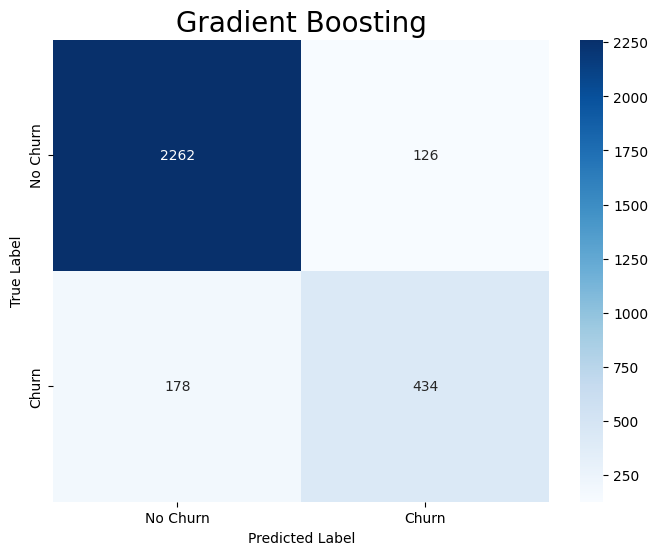

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# --- 1. Importar librerías para graficar ---
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Crear el pipeline que integra SMOTE y el clasificador
pipeline_gb = Pipeline([
    ('sampler', SMOTE(random_state=42)),
    ('classifier', GradientBoostingClassifier(
        n_estimators=261,
        learning_rate=0.03643803195448914,
        max_depth=5,
        min_samples_split=8,
        min_samples_leaf=6,
        subsample=0.7970512036903703,
        random_state=42
    ))
])

# 3. Entrenar el pipeline completo
pipeline_gb.fit(X_train, y_train)

# 4. Evaluar sobre el conjunto de prueba original
y_pred = pipeline_gb.predict(X_test)
y_pred_proba = pipeline_gb.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")


# --- 5. Graficar la Matriz de Confusión ---
# Definir las etiquetas de los ejes
labels = ['No Churn', 'Churn']

# Crear la figura
plt.figure(figsize=(8, 6))

# Usar seaborn para crear el heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)

# Añadir títulos y etiquetas
plt.title('Gradient Boosting', fontsize=20)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Mostrar el gráfico
plt.show()

(OPTUNA_XGB)

/home/ander/miniconda3/envs/ML/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [17:40:24] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


AUC Score: 0.9363
Accuracy: 0.8983

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.92      0.96      0.94      2388
       Churn       0.80      0.67      0.73       612

    accuracy                           0.90      3000
   macro avg       0.86      0.81      0.83      3000
weighted avg       0.89      0.90      0.89      3000

Sensibilidad: 0.6683
Especificidad: 0.9573
G-mean: 0.7998


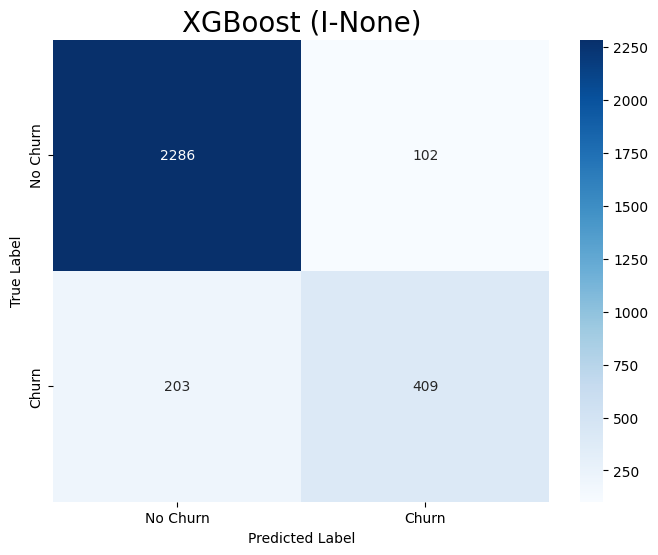

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# --- 1. Importar librerías para graficar ---
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Definir y entrenar el modelo
best_xgb = XGBClassifier(
    n_estimators=108,
    learning_rate=0.09830372052041464,
    max_depth=10,
    min_child_weight=2,
    subsample=0.7373717489359468,
    colsample_bytree=0.7679078375986028,
    gamma=4.519428792014974,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
best_xgb.fit(X_train, y_train)

# 3. Evaluar sobre el conjunto de prueba
y_pred = best_xgb.predict(X_test)
y_pred_proba = best_xgb.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")


# --- 4. Graficar la Matriz de Confusión ---
# Definir las etiquetas de los ejes
labels = ['No Churn', 'Churn']

# Crear la figura
plt.figure(figsize=(8, 6))

# Usar seaborn para crear el heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)

# Añadir títulos y etiquetas
plt.title('XGBoost (I-None)', fontsize=20)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Mostrar el gráfico
plt.show()

(OPTUNA_LGBM)

[LightGBM] [Info] Number of positive: 9603, number of negative: 9554
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001509 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2803
[LightGBM] [Info] Number of data points in the train set: 19157, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.501279 -> initscore=0.005116
[LightGBM] [Info] Start training from score 0.005116
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

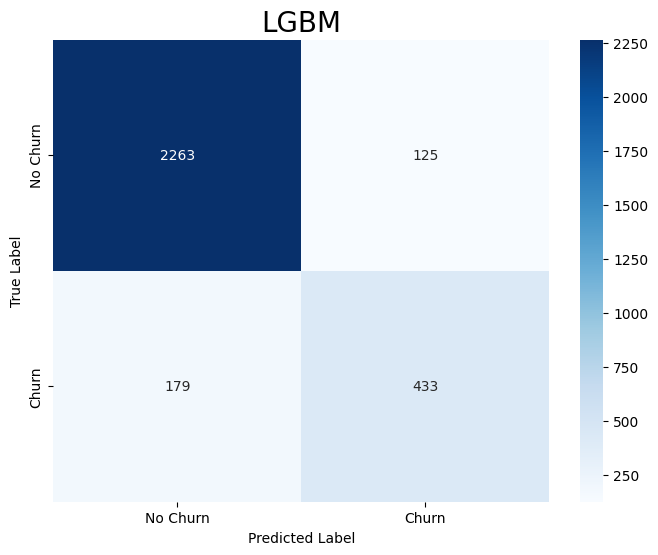

In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import ADASYN

# --- 1. Importar librerías para graficar ---
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Crear el pipeline que integra ADASYN y el clasificador
pipeline_lgbm = Pipeline([
    ('sampler', ADASYN(random_state=42)),
    ('classifier', LGBMClassifier(
        n_estimators=157,
        learning_rate=0.05320213755207298,
        max_depth=6,
        min_child_samples=17,
        subsample=0.9669128821218812,
        colsample_bytree=0.7484949223442707,
        reg_alpha=0.6488953630452698,
        reg_lambda=0.8732792139771435,
        random_state=42
    ))
])

# 3. Entrenar el pipeline completo
pipeline_lgbm.fit(X_train, y_train)

# 4. Evaluar sobre el conjunto de prueba original
y_pred = pipeline_lgbm.predict(X_test)
y_pred_proba = pipeline_lgbm.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")


# --- 5. Graficar la Matriz de Confusión ---
# Definir las etiquetas de los ejes
labels = ['No Churn', 'Churn']

# Crear la figura
plt.figure(figsize=(8, 6))

# Usar seaborn para crear el heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)

# Añadir títulos y etiquetas
plt.title('LGBM', fontsize=20)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Mostrar el gráfico
plt.show()

(OPTUNA_LR)

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import ADASYN

# 1. Crear el pipeline que integra ADASYN y el clasificador
pipeline_lr = Pipeline([
    ('sampler', ADASYN(random_state=42)),
    ('classifier', LogisticRegression(
        C=9.913728258413286,
        penalty='l1',
        solver='liblinear',
        class_weight=None,
        random_state=42
    ))
])

# 2. Entrenar el pipeline completo
pipeline_lr.fit(X_train, y_train)

# 3. Evaluar sobre el conjunto de prueba original
y_pred = pipeline_lr.predict(X_test)
y_pred_proba = pipeline_lr.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.8770
Accuracy: 0.8180

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.94      0.82      0.88      2388
       Churn       0.54      0.80      0.64       612

    accuracy                           0.82      3000
   macro avg       0.74      0.81      0.76      3000
weighted avg       0.86      0.82      0.83      3000

Sensibilidad: 0.7958
Especificidad: 0.8237
G-mean: 0.8096


(OPTUNA_ExTr)

In [12]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report

# Definir y entrenar el modelo
best_et = ExtraTreesClassifier(
    n_estimators=375,
    max_depth=14,
    min_samples_split=15,
    min_samples_leaf=2,
    max_features='log2',
    random_state=42
)
best_et.fit(X_train, y_train)

# Evaluar sobre el conjunto de prueba
y_pred = best_et.predict(X_test)
y_pred_proba = best_et.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_pred_proba)
accuracy = accuracy_score(y_test, y_pred)

print(f"AUC Score: {auc_score:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0
gmean = (sensibilidad * especificidad) ** 0.5

print(f"Sensibilidad: {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"G-mean: {gmean:.4f}")

AUC Score: 0.9314
Accuracy: 0.8890

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.97      0.93      2388
       Churn       0.82      0.59      0.68       612

    accuracy                           0.89      3000
   macro avg       0.86      0.78      0.81      3000
weighted avg       0.88      0.89      0.88      3000

Sensibilidad: 0.5882
Especificidad: 0.9661
G-mean: 0.7538


### Submissions

In [ ]:
#Submit predictions

test = pd.read_csv("/home/ander/Documentos/Universidad/ML/proyecto/test.csv")
test1 = test.drop(columns=["Surname", "id", "CustomerId"])

test_encoded = test1.copy()
for column in categorical_columns:
    one = encoders[column]
    encoded = one.transform(test_encoded[[column]])
    encoded_df = pd.DataFrame(encoded, columns=one.get_feature_names_out([column]), index=test_encoded.index)
    test_encoded = pd.concat([test_encoded.drop(column, axis=1), encoded_df], axis=1)

# Gender column
test_encoded['Gender'] = test_encoded['Gender'].map({'Male': 0, 'Female': 1})

# Asegura columnas y orden
test_encoded = test_encoded[X_train.columns]

# Realiza las predicciones
test_pred = best_brf.predict(test_encoded)
test_pred_proba = best_brf.predict_proba(test_encoded)[:, 1]

# Prepara el archivo de submit
submit = pd.DataFrame({
    "id": test["id"],
    "Exited": test_pred_proba
})

# Guarda el archivo
submit.to_csv("brf_250.csv", index=False)
print("Archivo de submit guardado como submission_brf_250.csv")


In [50]:
# ...existing code...
def plot_roc_by_auc_paletas_separadas(X_train, X_test, y_train, y_test):
    """
    Genera dos figuras independientes para las curvas ROC.
    - La primera figura muestra los modelos con mayor rendimiento.
    - La segunda figura muestra los modelos con menor rendimiento.
    El mejor modelo de cada grupo tiene línea continua y mayor grosor;
    el resto usan estilos y colores diferenciados. Se mantiene una
    secuencia continua de estilos entre ambas gráficas.
    Nota: esta función asume que las variables globales de modelos optimizados
    (best_rf, pipeline_gb, pipeline_lgbm, best_et, best_eec, best_rus,
    best_bbc, best_brf, best_xgb, pipeline_lr) están definidas en el entorno.
    """
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
    from itertools import cycle
    from sklearn.metrics import roc_curve, auc
    from xgboost import XGBClassifier
    from imblearn.over_sampling import SMOTE, ADASYN
    import warnings
    warnings.filterwarnings("ignore")

    # --- Preparación containers ---
    roc_data = {}
    auc_dict = {}

    # Intento cargar ROC precalculado (opcional)
    try:
        roc_tpot = pd.read_csv('/home/ander/Documentos/Universidad/ML/proyecto/Optuna/roc_modelo.csv')
        if {'fpr', 'tpr'}.issubset(roc_tpot.columns):
            fpr_tpot, tpr_tpot = roc_tpot['fpr'].values, roc_tpot['tpr'].values
            auc_tpot = auc(fpr_tpot, tpr_tpot)
            auc_dict['LightGBM(TPOT)'] = auc_tpot
            roc_data['LightGBM(TPOT)'] = (fpr_tpot, tpr_tpot)
            print("Modelo LightGBM(TPOT) cargado desde CSV.")
    except Exception as e:
        print(f'No se pudo cargar roc_modelo.csv: {e}')

    # Hiperparámetros XGBoost de respaldo
    xgb_i_none_params = {
        'n_estimators': 108, 'learning_rate': 0.09830372052041464, 'max_depth': 10,
        'min_child_weight': 2, 'subsample': 0.7373717489359468,
        'colsample_bytree': 0.7679078375986028, 'gamma': 4.519428792014974,
        'random_state': 42, 'use_label_encoder': False, 'eval_metric': 'logloss'
    }
    xgb_p_params = {
        'n_estimators': 200, 'learning_rate': 0.1107, 'max_depth': 9, 'min_child_weight': 10,
        'subsample': 0.8266, 'colsample_bytree': 0.7236, 'gamma': 4.514, 'random_state': 42,
        'use_label_encoder': False, 'eval_metric': 'logloss'
    }

    # --- Construcción del diccionario de modelos ---
    # Si alguna variable no existe, se ignora y se intenta continuar.
    models = {}
    possible_models = {
        'RandomForest': 'best_rf',
        'GradientBoosting': 'pipeline_gb',
        'LightGBM': 'pipeline_lgbm',
        'ExtraTrees': 'best_et',
        'EasyEnsemble': 'best_eec',
        'RUSBoost': 'best_rus',
        'BalancedBagging': 'best_bbc',
        'BalancedRF': 'best_brf',
        'XGBoost (Optuna)': 'best_xgb',
        'LogisticRegression': 'pipeline_lr',
        'XGBoost (I - None)': None  # se instanciará abajo
    }
    g = globals()
    for name, varname in possible_models.items():
        if varname is None:
            models[name] = XGBClassifier(**xgb_i_none_params)
        else:
            if varname in g:
                models[name] = g[varname]
            else:
                print(f"Advertencia: variable '{varname}' no encontrada; '{name}' omitido si no puede instanciarse.")

    # Intentar crear variantes XGBoost con balanceo (SMOTE / ADASYN)
    try:
        smote = SMOTE(random_state=42)
        X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
        xgb_smote = XGBClassifier(**xgb_p_params).fit(X_train_sm, y_train_sm)
        models['XGBoost (P - SMOTE)'] = xgb_smote

        adasyn = ADASYN(random_state=42)
        X_train_ad, y_train_ad = adasyn.fit_resample(X_train, y_train)
        xgb_adasyn = XGBClassifier(**xgb_p_params).fit(X_train_ad, y_train_ad)
        models['XGBoost (P - ADASYN)'] = xgb_adasyn
        print("Modelos XGBoost con SMOTE y ADASYN creados.")
    except Exception as e:
        print(f"Error creando variantes XGB con balanceo: {e}")

    # --- Calcular ROC y AUC para cada modelo ---
    for name, model in list(models.items()):
        if name in auc_dict:
            continue
        try:
            # Si es un pipeline que ya fue entrenado, skip; si no, entrenar.
            trained = False
            if hasattr(model, "predict_proba"):
                # muchos objetos entrenados tendrán clases_
                trained = hasattr(model, "classes_")
            if not trained:
                # Intentar entrenar (algunos 'models' pueden ser pipelines que esperan X_train en su forma)
                try:
                    model.fit(X_train, y_train)
                except Exception:
                    # si no puede entrenar, eliminar del diccionario y continuar
                    print(f"No se pudo entrenar {name}; se omite.")
                    del models[name]
                    continue
            # Predecir probabilidades
            y_pred_proba = model.predict_proba(X_test)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
            auc_val = auc(fpr, tpr)
            auc_dict[name] = auc_val
            roc_data[name] = (fpr, tpr)
        except Exception as e:
            print(f"No se pudo calcular ROC para {name}: {e}")

    if not auc_dict:
        print("No se pudo calcular el AUC para ningún modelo. Saliendo.")
        return

    # --- Preparación para graficar ---
    sorted_models = sorted(auc_dict.items(), key=lambda item: item[1], reverse=True)
    best_model_name = sorted_models[0][0]

    split_point = max(1, len(sorted_models) // 2)
    top_half_models = sorted_models[:split_point]
    bottom_half_models = sorted_models[split_point:]

    best_model_bottom_name = bottom_half_models[0][0] if bottom_half_models else None

    # Paletas y estilos
    colors_top_list = ['#0077BB', '#009988', '#EE3377', '#332288', '#001146', '#55A868', '#AA4499']
    colors_bottom_list = ['#D55E00', '#004D40', '#E69F00', '#56B4E9', '#CC79A7', '#F0E442', '#663300']

    top_other_names = [m[0] for m in top_half_models if m[0] != best_model_name]
    color_map_top = {name: colors_top_list[i % len(colors_top_list)] for i, name in enumerate(top_other_names)}

    bottom_names = [m[0] for m in bottom_half_models if m[0] != best_model_bottom_name]
    color_map_bottom = {name: colors_bottom_list[i % len(colors_bottom_list)] for i, name in enumerate(bottom_names)}

    linestyles_list = ['--', '-.', ':', (0, (3, 5, 1, 5)), (0, (5, 1)), (0, (1, 1))]
    shared_ls_cycle = cycle(linestyles_list)

    # === FIGURA 1: MODELOS DE MAYOR RENDIMIENTO ===
    fig1, ax1 = plt.subplots(figsize=(12, 10))
    for name, roc_auc in top_half_models:
        fpr, tpr = roc_data.get(name, (None, None))
        if fpr is None:
            continue
        label = f'{name} (AUC = {roc_auc:.3f})'
        if name == best_model_name:
            ax1.plot(fpr, tpr, color='#d62728', linestyle='-', lw=4, label=label, zorder=10)
        else:
            ax1.plot(fpr, tpr, color=color_map_top.get(name, '#444444'), linestyle=next(shared_ls_cycle), lw=2.5, label=label)

    # Zoom inset figura 1
    axins1 = inset_axes(ax1, width="40%", height="35%", loc='center')
    zoom_cycle_1 = cycle(linestyles_list)
    for name, _ in top_half_models:
        fpr, tpr = roc_data.get(name, (None, None))
        if fpr is None:
            continue
        if name == best_model_name:
            axins1.plot(fpr, tpr, color='#d62728', linestyle='-', lw=4)
        else:
            axins1.plot(fpr, tpr, color=color_map_top.get(name, '#444444'), linestyle=next(zoom_cycle_1), lw=2.5)
    axins1.set_xlim(0.0, 0.2); axins1.set_ylim(0.8, 1.0)
    axins1.tick_params(axis='x', labelsize=12); axins1.tick_params(axis='y', labelsize=12)
    axins1.grid(alpha=0.5)
    axins1.set_xticks(np.arange(0, 0.21, 0.1)); axins1.set_yticks(np.arange(0.8, 1.01, 0.1))
    mark_inset(ax1, axins1, loc1=1, loc2=3, fc="none", ec="0.6")

    ax1.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle=':')
    ax1.set_xlim([-0.01, 1.0]); ax1.set_ylim([0.0, 1.01])
    ax1.set_xlabel('False Positive Rate', fontsize=18)
    ax1.set_ylabel('True Positive Rate', fontsize=18)
    ax1.tick_params(axis='both', which='major', labelsize=16) # Aumenta el tamaño de los números en los ejes

    ax1.grid(alpha=0.6)
    ax1.legend(loc='lower right', fontsize=17)
    fig1.tight_layout()

    # === FIGURA 2: MODELOS DE MENOR RENDIMIENTO ===
    if bottom_half_models:
        fig2, ax2 = plt.subplots(figsize=(12, 10))
        for name, roc_auc in bottom_half_models:
            fpr, tpr = roc_data.get(name, (None, None))
            if fpr is None:
                continue
            label = f'{name} (AUC = {roc_auc:.3f})'
            if name == best_model_bottom_name:
                ax2.plot(fpr, tpr, color=colors_bottom_list[0], linestyle='-', lw=4, label=label, zorder=10)
            else:
                ax2.plot(fpr, tpr, color=color_map_bottom.get(name, '#666666'), linestyle=next(shared_ls_cycle), lw=2.5, label=label)

        # Zoom inset figura 2
        axins2 = inset_axes(ax2, width="40%", height="35%", loc='center')
        zoom_cycle_2 = cycle(linestyles_list)
        for name, _ in bottom_half_models:
            fpr, tpr = roc_data.get(name, (None, None))
            if fpr is None:
                continue
            if name == best_model_bottom_name:
                axins2.plot(fpr, tpr, color=colors_bottom_list[0], linestyle='-', lw=4)
            else:
                axins2.plot(fpr, tpr, color=color_map_bottom.get(name, '#666666'), linestyle=next(zoom_cycle_2), lw=2.5)

        axins2.set_xlim(0.0, 0.2); axins2.set_ylim(0.8, 1.0)
        axins2.tick_params(axis='x', labelsize=12); axins2.tick_params(axis='y', labelsize=12)
        axins2.grid(alpha=0.5)
        axins2.set_xticks(np.arange(0, 0.21, 0.1)); axins2.set_yticks(np.arange(0.8, 1.01, 0.1))
        mark_inset(ax2, axins2, loc1=1, loc2=3, fc="none", ec="0.6")

        ax2.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle=':')
        ax2.set_xlim([-0.01, 1.0]); ax2.set_ylim([0.0, 1.01])
        ax2.set_xlabel('False Positive Rate', fontsize=18)
        ax2.set_ylabel('True Positive Rate', fontsize=18)
        ax2.tick_params(axis='both', which='major', labelsize=16) # Aumenta el tamaño de los números en los ejes

        ax2.grid(alpha=0.6)
        ax2.legend(loc='lower right', fontsize=17)
        fig2.tight_layout()

    plt.show()
# ...existing code...

Modelo LightGBM(TPOT) cargado desde CSV.
Modelos XGBoost con SMOTE y ADASYN creados.


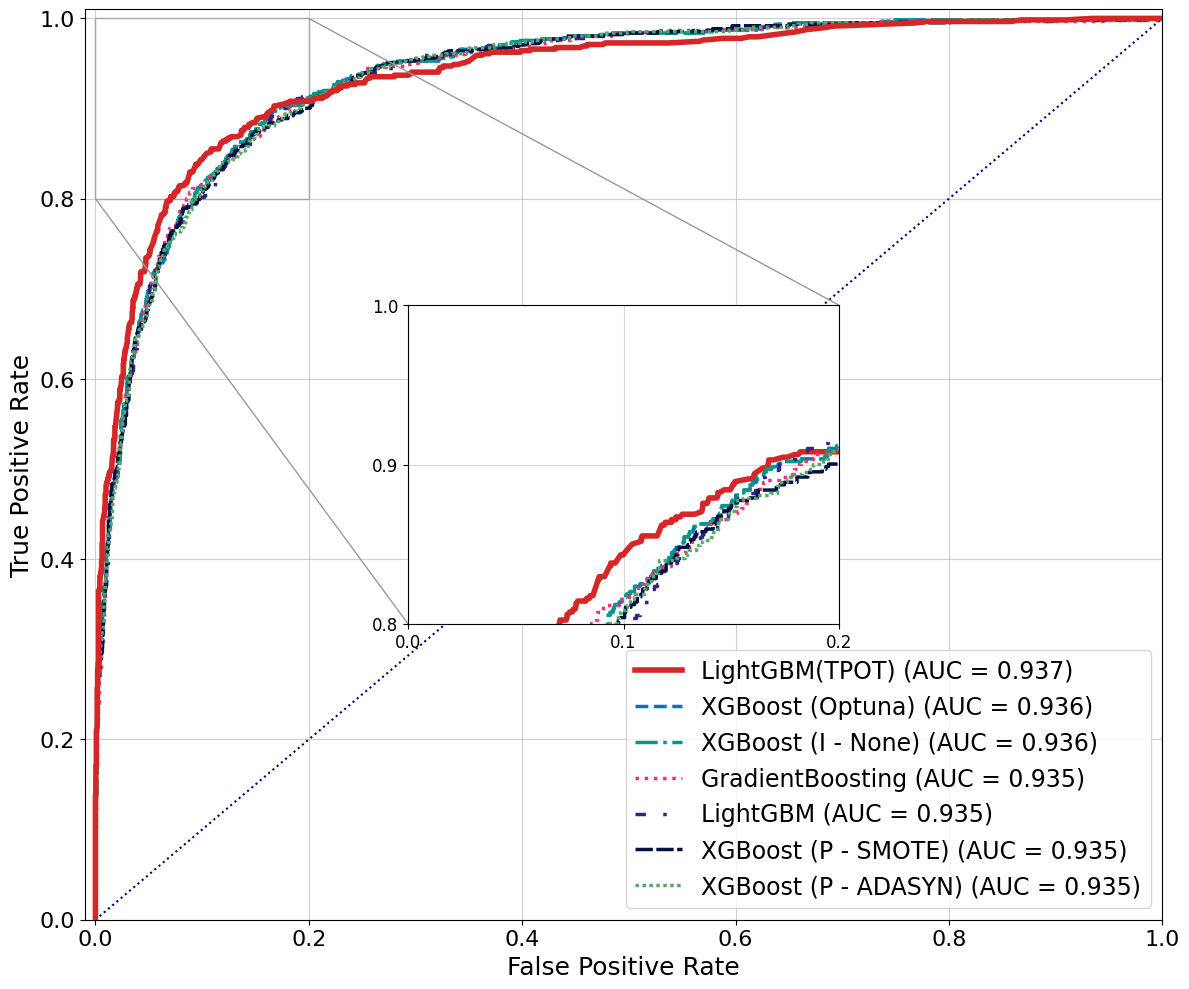

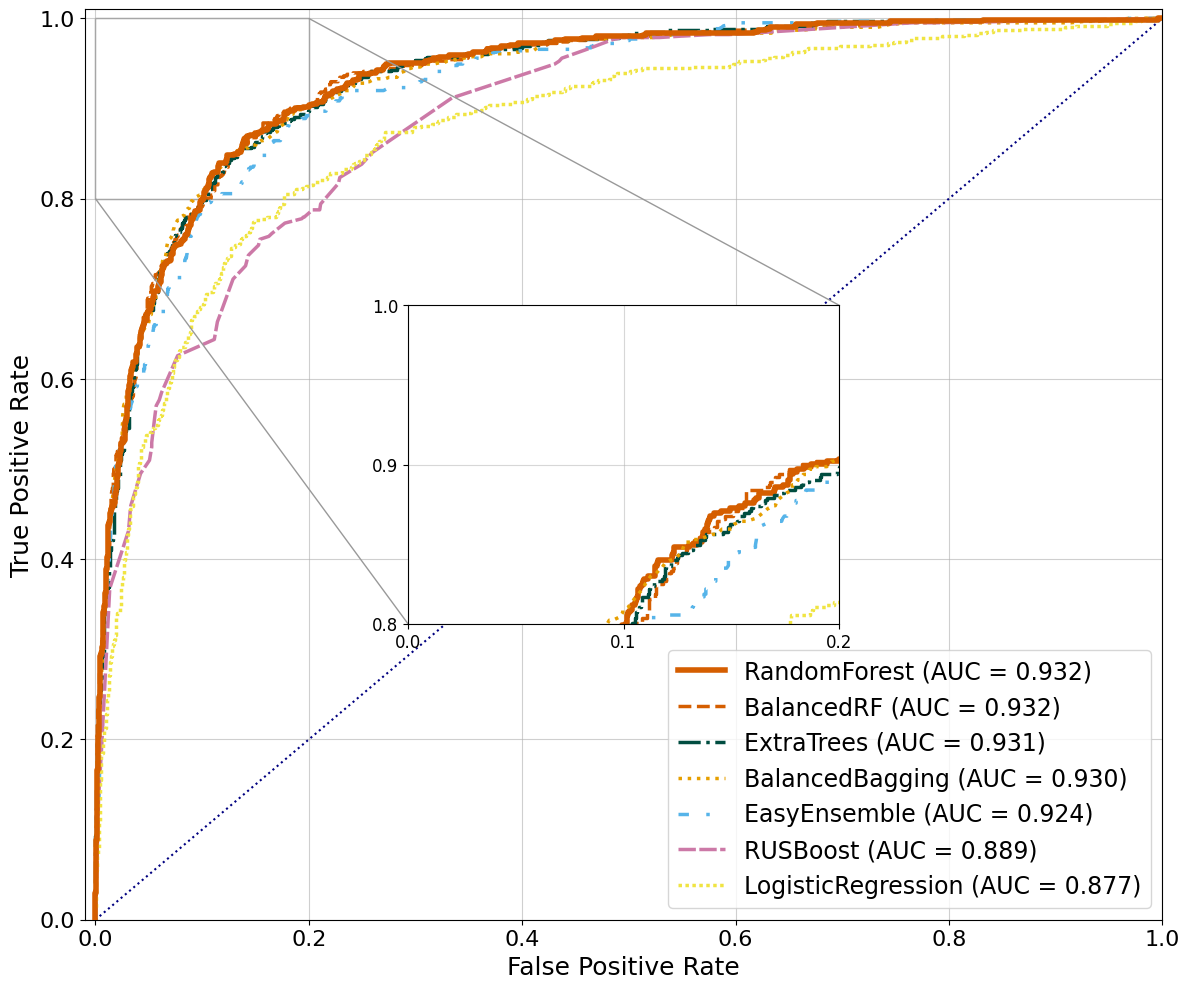

In [51]:
plot_roc_by_auc_paletas_separadas(X_train, X_test, y_train, y_test)